# Peak trace svr regressor

In [2]:
from __future__ import annotations
import argparse
import json
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from concentration_split import grouped_concentration_split, regression_metrics


In [4]:
matplotlib.use('Agg')
PACKAGE = Path.cwd().parent
ROOT = PROJECT = PROJECT_ROOT = PACKAGE / 'work'
SETTINGS = argparse.Namespace(tag='double_ellipse_S843_theta205_D6p52_random10000_logC_m10p5_m8_t7200_dt60_allparam_noise0p05_spectrum0p01', 
                              split_seed=7, sections=8, cache_size_mb=4096, fixed_c=1.0, fixed_gamma=0.01, fixed_epsilon=0.1)


In [5]:
def evaluate(c_value: float, gamma: float, epsilon: float, stage: str) -> None:
    global best
    model = SVR(kernel='rbf', C=c_value, gamma=gamma, epsilon=epsilon, cache_size=args.cache_size_mb)
    model.fit(train, target[splits.train])
    prediction = model.predict(validation)
    rmse = float(np.sqrt(np.mean((prediction - target[splits.val]) ** 2)))
    row = {'search_stage': stage, 'C': c_value, 'gamma': gamma, 'epsilon': epsilon, 'validation_rmse_log10': rmse, 'n_support_vectors': int(model.support_.size)}
    search_rows.append(row)
    if best is None or rmse < best['validation_rmse_log10']:
        best = {**row, 'model': model}
    print(json.dumps(row), flush=True)


In [6]:
args = SETTINGS
data = PROJECT / ('langmuir_spectral_images_' + args.tag)
peak_dir = ROOT / 'models' / ('peak_tracking_' + args.tag)
out = ROOT / 'models' / ('peak_trace_svr_' + args.tag)
figures = ROOT / 'figures' / ('peak_trace_svr_' + args.tag)

out.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)
metadata = pd.read_csv(data / 'spectral_image_metadata.csv')
peaks = np.load(peak_dir / 'peak_positions_nm.npy', mmap_mode='r').astype(np.float64)
features = peaks - peaks[:, :1]
target = np.log10(metadata.concentrationM.to_numpy(dtype=np.float64))

split_args = argparse.Namespace(split_seed=args.split_seed, test_fraction=0.15, val_fraction=0.15)
splits = grouped_concentration_split(metadata, split_args)
scaler = StandardScaler().fit(features[splits.train])
train = scaler.transform(features[splits.train])
validation = scaler.transform(features[splits.val])
test_features = scaler.transform(features[splits.test])

search_rows = []
best = None
evaluate(args.fixed_c, args.fixed_gamma, args.fixed_epsilon, 'fixed')
selection = 'C, gamma, and epsilon fixed by the reference experiment; final model uses training split only'
model = best['model']
prediction = model.predict(test_features)
metrics = regression_metrics(target[splits.test], prediction)
test = pd.DataFrame({'recordId': metadata.recordId.to_numpy()[splits.test], 'concentrationM': metadata.concentrationM.to_numpy()[splits.test], 'true_log10_concentration': target[splits.test], 'pred_log10_concentration': prediction, 'pred_concentrationM': 10.0 ** prediction})
test.to_csv(out / 'test_predictions.csv', index=False)

pd.DataFrame(search_rows).to_csv(out / 'validation_search.csv', index=False)
pd.DataFrame([{'method': 'Peak trace + RBF-SVR', 'n_test': len(test), 'C': best['C'], 'gamma': best['gamma'], 'epsilon': best['epsilon'], 'n_support_vectors': best['n_support_vectors'], **metrics}]).to_csv(out / 'test_metrics.csv', index=False)


{"search_stage": "fixed", "C": 1.0, "gamma": 0.01, "epsilon": 0.1, "validation_rmse_log10": 0.16406198307360978, "n_support_vectors": 2725}


In [7]:
edges = np.linspace(-10.5, -8.0, args.sections + 1)

section_rows = []

for section in range(args.sections):
    mask = (test.true_log10_concentration >= edges[section]) & (test.true_log10_concentration <= edges[section + 1] if section == args.sections - 1 else test.true_log10_concentration < edges[section + 1])
    error = (test.loc[mask, 'pred_log10_concentration'] - test.loc[mask, 'true_log10_concentration']).to_numpy()
    section_rows.append({'section': section + 1, 'log10_lower_M': edges[section], 'log10_upper_M': edges[section + 1], 'n_test': int(mask.sum()), 'rmse_log10_concentration': float(np.sqrt(np.mean(error ** 2))), 'mae_log10_concentration': float(np.mean(np.abs(error))), 'bias_log10_concentration': float(np.mean(error))})

pd.DataFrame(section_rows).to_csv(out / 'rmse_by_concentration_section.csv', index=False)

summary = {'feature': '51 tracked peak shifts relative to the t=0 peak position', 'model': 'StandardScaler fitted on training records, then epsilon-SVR with an RBF kernel', 'selection': selection, 'selected_C': best['C'], 'selected_gamma': best['gamma'], 'selected_epsilon': best['epsilon'], 'n_support_vectors': best['n_support_vectors'], 'split': {'seed': args.split_seed, 'n_train': len(splits.train), 'n_validation': len(splits.val), 'n_test': len(splits.test)}, 'metrics': metrics}

(out / 'experiment_summary.json').write_text(json.dumps(summary, indent=2))

824

{
  "feature": "51 tracked peak shifts relative to the t=0 peak position",
  "model": "StandardScaler fitted on training records, then epsilon-SVR with an RBF kernel",
  "selection": "C, gamma, and epsilon fixed by the reference experiment; final model uses training split only",
  "selected_C": 1.0,
  "selected_gamma": 0.01,
  "selected_epsilon": 0.1,
  "n_support_vectors": 2725,
  "split": {
    "seed": 7,
    "n_train": 7000,
    "n_validation": 1500,
    "n_test": 1500
  },
  "metrics": {
    "rmse_log10_concentration": 0.16009649918760607,
    "mae_log10_concentration": 0.11193414083251435,
    "r2_log10_concentration": 0.9513129717988922,
    "pearson_corr": 0.9754006525879902,
    "spearman_corr": 0.9745762980339102,
    "median_fold_error": 1.1856946449944072,
    "p90_fold_error": 1.9034743355411632
  }
}


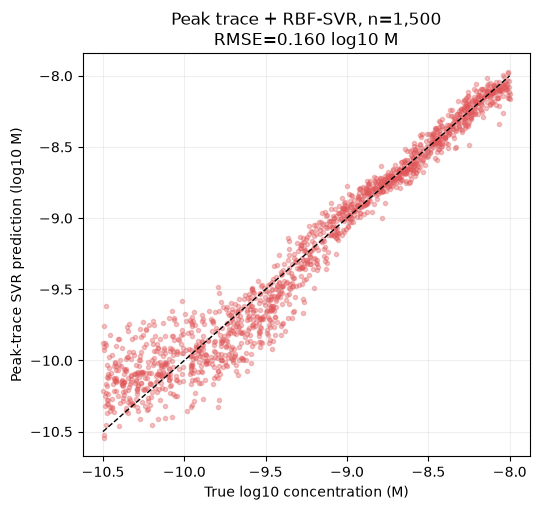

In [13]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.scatter(test.true_log10_concentration, test.pred_log10_concentration, s=9, alpha=0.35, color='#e15759')
ax.plot([-10.5, -8.0], [-10.5, -8.0], 'k--', linewidth=1)
ax.set(xlabel='True log10 concentration (M)', ylabel='Peak-trace SVR prediction (log10 M)', title=f"Peak trace + RBF-SVR, n={len(test):,}\nRMSE={metrics['rmse_log10_concentration']:.3f} log10 M")
ax.grid(alpha=0.2)
fig.tight_layout()

#fig.savefig(figures / 'test_prediction_vs_truth.svg')
#plt.close(fig)
print(json.dumps(summary, indent=2), flush=True)
